# Exercise: Doctor Who on holidays

*Doctor Who* is a British TV show. Since 2005, the BBC has shown a special episode almost every **Christmas Day**. Some years, it was on **New Year's Day**.

Do holiday episodes get more viewers? Today you use multiple regression to find out.

## Setup

In [1]:
library('tidymodels')

options(repr.plot.res = 250, repr.plot.height = 3, repr.plot.width = 5)

── Attaching packages ──────────────────────────────────────────────────────── tidymodels 1.4.1 ──
✔ broom        1.0.13     ✔ recipes      1.4.0 
✔ dials        1.4.4      ✔ rsample      1.3.2 
✔ dplyr        1.2.1      ✔ tailor       0.1.0 
✔ ggplot2      4.0.3      ✔ tidyr        1.3.2 
✔ infer        1.1.0      ✔ tune         2.1.0 
✔ modeldata    1.6.0      ✔ workflows    1.3.0 
✔ parsnip      1.6.1      ✔ workflowsets 1.1.1 
✔ purrr        1.2.2      ✔ yardstick    1.4.0 
── Conflicts ─────────────────────────────────────────────────────────── tidymodels_conflicts() ──
✖ tidyr::complete() masks hera::complete()
✖ purrr::discard()  masks scales::discard()
✖ dplyr::filter()   masks stats::filter()
✖ dplyr::lag()      masks stats::lag()
✖ recipes::step()   masks stats::step()
• Dig deeper into tidy modeling with R at https://www.tmwr.org


## The data

Each row is one episode, from 2005 to 2022.

| column | meaning |
|---|---|
| `episode_title` | name of the episode |
| `type` | `episode` or `special` |
| `first_aired` | date the episode was first on TV |
| `uk_viewers` | UK viewers, in millions |
| `rating` | audience score, 0–100 |

Source: [TidyTuesday, 2023-11-28](https://github.com/rfordatascience/tidytuesday/tree/main/data/2023/2023-11-28) (from Wikipedia, via the `datardis` package).

We make two new columns:

- `holiday`: 1 if the episode aired on December 25 or January 1, 0 if not.
- `year`: the air date as a number, like 2010.5 for the middle of 2010. `decimal_date()` does this.

In [2]:
drwho <- read.csv('https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2023/2023-11-28/drwho_episodes.csv')

drwho <- drwho |>
    mutate(
        first_aired = as.Date(first_aired),
        holiday = if_else(format(first_aired, '%m-%d') %in% c('12-25', '01-01'), 1, 0),
        year = lubridate::decimal_date(first_aired)
    )

drwho |> count(holiday)

  holiday n  
1 0       157
2 1        18

## 1. Look at the data

Plot `uk_viewers` (y-axis) against `first_aired` (x-axis). Color the points by `factor(holiday)`.

<details>
<summary>Hint</summary>

```R
ggplot(drwho, aes(x = first_aired, y = uk_viewers, color = factor(holiday))) +
    geom_point()
```

</details>

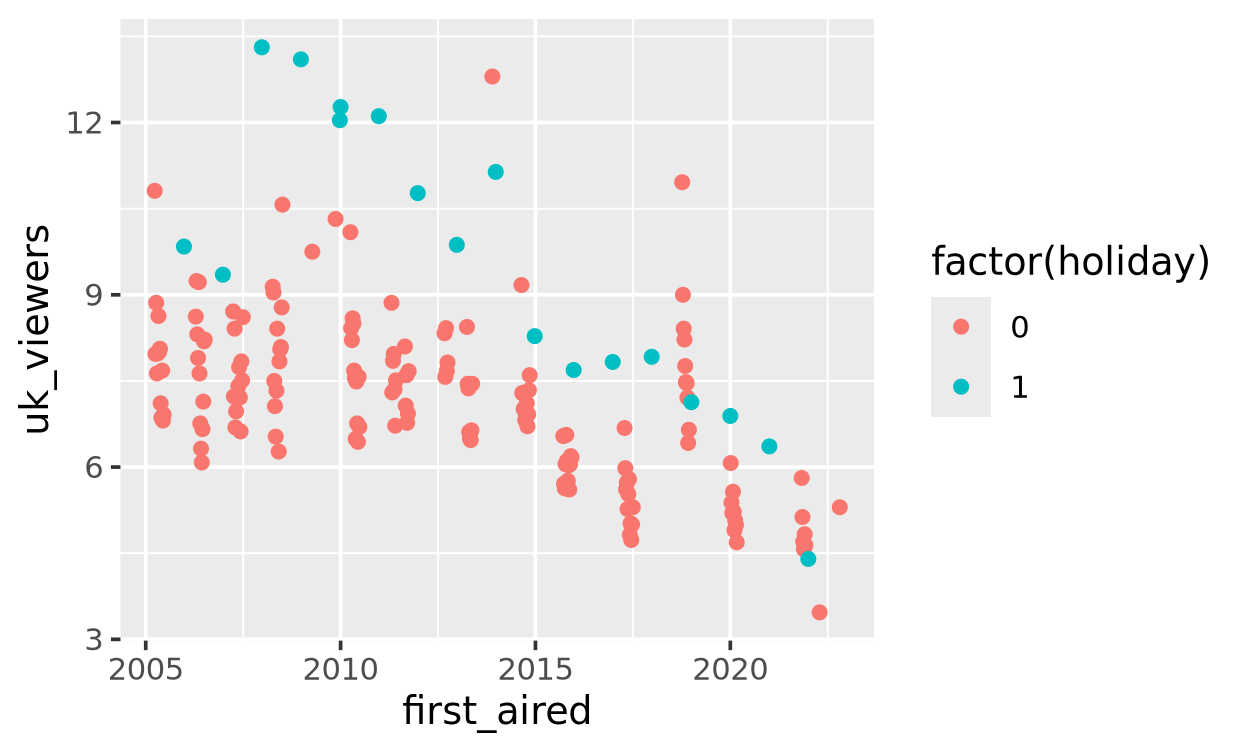

In [3]:
ggplot(drwho, aes(x = first_aired, y = uk_viewers, color = factor(holiday))) +
    geom_point()

What happens to the number of viewers over time? Where are the holiday points?

## 2. One predictor

Fit `uk_viewers ~ holiday` with `linear_reg()`. Save it as `fit_one` and show `tidy(fit_one)`.

<details>
<summary>Hint</summary>

```R
fit_one <- linear_reg() |> fit(uk_viewers ~ holiday, data = drwho)

fit_one
```

</details>

In [4]:
fit_one <- linear_reg() |> fit(uk_viewers ~ holiday, data = drwho)

fit_one

parsnip model object


Call:
stats::lm(formula = uk_viewers ~ holiday, data = data)

Coefficients:
(Intercept)      holiday  
      7.161        2.300  


**Check:** the `holiday` estimate should be about 2.3. What does this number mean, in words?

## 3. AI step: add `year`

Viewers go down over the years. We want to measure the marginal effect of `holiday` on viewership with a model that also factors in `year`.

Open a terminal and run `opencode`.

**Copy this prompt into opencode:**

```text
I am working in exercises/12-drwho-exercise.ipynb, with R and tidymodels.
The data frame drwho has a column uk_viewers (millions of viewers), a column
holiday (1 or 0), and a column year (the air date as a decimal year).

In the empty code cell in step 3, fit a linear regression of
uk_viewers ~ holiday + year with linear_reg(). Save it as fit_two and show
tidy(fit_two). Run the cell. Use tidymodels only. Do not change any other cells.
```

**Your assistant puts its code in the cell below and runs it.** Read the code. Does the formula have both `holiday` and `year`?

In [7]:
fit_two <- linear_reg() |> fit(uk_viewers ~ holiday + year, data = drwho)

tidy(fit_two)

  term        estimate    std.error   statistic p.value     
1 (Intercept) 379.4484005 38.72404194  9.798781 2.727092e-18
2 holiday       2.5295116  0.31721374  7.974155 2.050381e-13
3 year         -0.1849853  0.01924147 -9.613888 8.799150e-18

**Check:** the `holiday` estimate should be about 2.5. The `year` estimate should be about -0.19.

- What does the `year` estimate mean, in words?
- The `holiday` estimate changed from 2.3 to 2.5. Why? (Think about what "when the other predictor stays the same" means.)

## 4. Plot the model

Make a grid with `crossing(year = 2005:2023, holiday = c(0, 1))`. Predict on the grid with `fit_two` and bind the grid to the predictions.

Plot the data with `year` on the x-axis. Add the predictions as lines, colored by `factor(holiday)`.

<details>
<summary>Hint</summary>

```R
grid <- crossing(year = 2005:2023, holiday = c(0, 1))

preds <- fit_two |>
    predict(new_data = grid) |>
    bind_cols(grid)

ggplot(drwho, aes(x = year, y = uk_viewers, color = factor(holiday))) +
    geom_point() +
    geom_line(data = preds, aes(y = .pred))
```

</details>

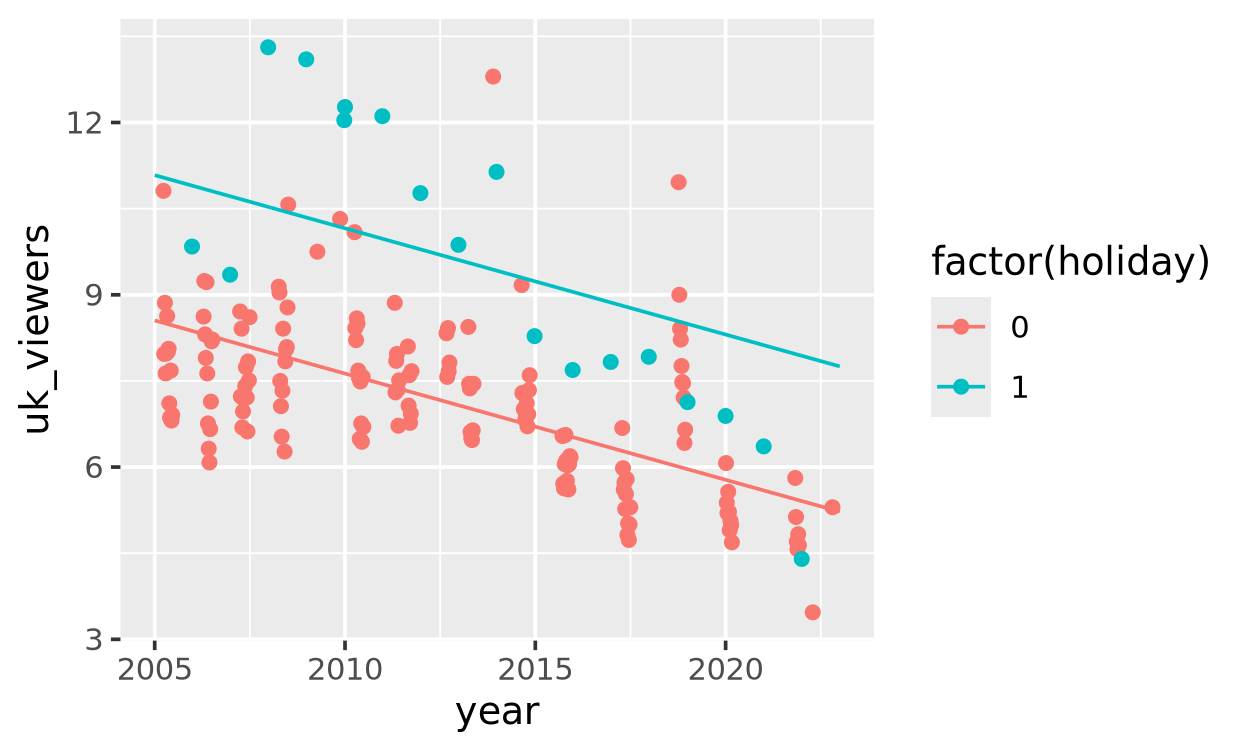

In [6]:
grid <- crossing(year = 2005:2023, holiday = c(0, 1))

preds <- fit_two |>
    predict(new_data = grid) |>
    bind_cols(grid)

ggplot(drwho, aes(x = year, y = uk_viewers, color = factor(holiday))) +
    geom_point() +
    geom_line(data = preds, aes(y = .pred))

**Check:** you should see two parallel lines that go down. The holiday line is about 2.5 million viewers higher.

## 5. Bonus: better or just bigger?

More people watch on holidays. But do they *like* the holiday episodes more?

Fit `rating ~ holiday + year`. Look at the `holiday` estimate.

In [8]:
fit_rating <- linear_reg() |> fit(rating ~ holiday + year, data = drwho)

tidy(fit_rating)

  term        estimate    std.error   statistic  p.value     
1 (Intercept) 854.2207048 82.84323597 10.3112909 1.029956e-19
2 holiday      -0.3030026  0.67862267 -0.4464965 6.558003e-01
3 year         -0.3827139  0.04116372 -9.2973595 6.440392e-17

**Check:** the `holiday` estimate should be close to 0 (about -0.3). Holiday episodes get more viewers, but not better scores.